# Policy Gradient - Reinforce

In [1]:
import torch
import numpy as np
import torch.nn as nn
import matplotlib.pyplot as plt

In [2]:
class Policy(nn.Module):
  def __init__(self, input_dim , hidden_dim=16 , output_dim=1):
    super(Policy ,self).__init__()
    layer1 = nn.Linear(input_dim , hidden_dim , bias = True)
    relu = nn.ReLU()
    layer2 = nn.Linear(hidden_dim , output_dim , bias = True)
    self.estimator = nn.Sequential(layer1 , relu , layer2)
  def forward(self , state):
    state = torch.tensor(state) #tabdil bordar vijegi state az halat array numpy b tensor
    pred = self.estimator(state) # meghdar x be ezaye action haye momken dar state feli
    return pred

In [8]:
class PG_Agent:
  def __init__(self, state_size , action_size , learning_rate=0.001 , discount_factor=0.95):
    self.state_size = state_size
    self.action_size = action_size
    self.learning_rate = learning_rate
    self.discount_factor = discount_factor

    self.policy = Policy(state_size , output_dim = action_size)
    self.loss_fn = nn.CrossEntropyLoss(reduction='none') #reduction=non yani loss har sample ro jodagane negah dar
    self.optimizer = torch.optim.Adam(self.policy.parameters() , lr = learning_rate)

  def select_action(self , state):
    logits = self.policy(state) #
    probs = torch.nn.functional.softmax(logits) #tabdil khoroji shabake be ehtemal
    action = torch.multinomial(probs , num_samples=1).detach().numpy()[0] # بر اساس خروجی شبکه که احتمال عمل های ممکن در وضعیت فعلی است یک عمل را بصورت تصادفی انتخاب میکنیم. البته دفعات انتخاب تصادفی عملی با احتمال بزرگتر در بلند مدت بیشتر است.
    return action

  def reward_to_go(self, rewards):
    rewards2go = np.array(rewards, dtype=float)
    for i in range(2 , len(rewards)+1):
      rewards2go[-i] = rewards[-i] + self.discount_factor * rewards2go[-i+1] #mohasebe az akhar be aval
    return rewards2go



  def update(self , states , actions , rewards):
    actions = torch.tensor(actions)
    rewardtogo = self.reward_to_go(rewards)
    rewardtogo = torch.tensor(rewardtogo)
    self.optimizer.zero_grad()
    logits = self.policy(states)
    log_probs = - self.loss_fn(logits , actions) # ro sample ha miangin nagire
    loss = - log_probs * rewardtogo
    loss.sum().backward()
    self.optimizer.step()

In [9]:
# env
import gymnasium as gym
import numpy as np

n_episodes = 1500
total_reward =[]
env = gym.make('CartPole-v1')
agent = PG_Agent(env.observation_space._shape[0] , env.action_space.n)

for i in range(n_episodes):
    state , info = env.reset()
    episode_rewards=[]
    episode_actions=[]
    episode_states=[]

    while True: # gam haye yek episode
        action=agent.select_action(state)
        episode_actions.append(action)
        episode_states.append(state)

        next_state, reward, terminated, truncated, info = env.step(action)
        episode_rewards.append(reward)
        state=next_state
        if terminated:
            break
    agent.update(episode_states , episode_actions , episode_rewards)
    total_reward.append(np.sum(episode_rewards))

/tmp/ipykernel_9396/558124810.py:14: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  probs = torch.nn.functional.softmax(logits) #tabdil khoroji shabake be ehtemal


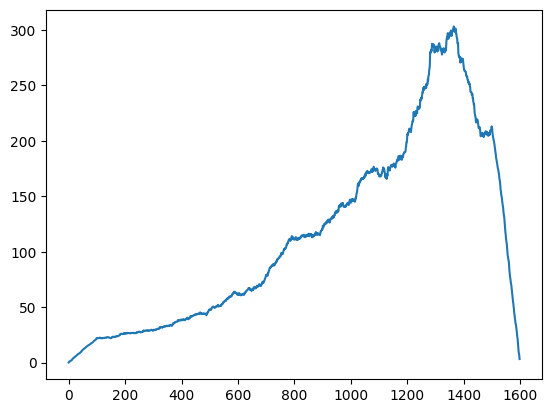

In [10]:
plt.plot(np.convolve(total_reward, np.ones(100) / 100))